In [2]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

train_data = pd.read_csv('/content/sign_mnist_train.csv')
test_data = pd.read_csv('/content/sign_mnist_test.csv')

print("Training shape : ", train_data.shape)
print("Testing shape : ", test_data.shape)

Training shape :  (2417, 785)
Testing shape :  (2416, 785)


In [4]:
x_train = train_data.drop('label', axis = 1).values/255.0
x_test = test_data.drop('label', axis =1).values/255.0
y_train = train_data['label'].values
y_test = test_data['label'].values


print("x Training data shape : ", x_train.shape)
print("x Testing data shape : ", x_test.shape)
print("y Training data shape : ", y_train.shape)
print("y Testing data shape : ", y_test.shape)

x Training data shape :  (2417, 784)
x Testing data shape :  (2416, 784)
y Training data shape :  (2417,)
y Testing data shape :  (2416,)


In [5]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)
print("x Training data shape : ", x_train.shape)
print("x Testing data shape : ", x_test.shape)

x Training data shape :  (2417, 28, 28, 1)
x Testing data shape :  (2416, 28, 28, 1)


In [10]:
# model = Sequential([
#     Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
#     MaxPooling2D((2,2)),
#     Flatten(),
#     Dense(64, activation='relu'),
#     Dense(25, activation='softmax')
# ])
# model.summary()





Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 348,121 (1.33 MB)

 Trainable params: 348,121 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [13]:
history = model.fit(x_train,y_train,validation_split=0.1, epochs=10)

Epoch 1/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7425 - loss: 0.9738 - val_accuracy: 0.7190 - val_loss: nan
Epoch 2/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7862 - loss: 0.8093 - val_accuracy: 0.7314 - val_loss: nan
Epoch 3/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8170 - loss: 0.6964 - val_accuracy: 0.7603 - val_loss: nan
Epoch 4/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8446 - loss: 0.6104 - val_accuracy: 0.7562 - val_loss: nan
Epoch 5/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8703 - loss: 0.5296 - val_accuracy: 0.7686 - val_loss: nan
Epoch 6/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.8878 - loss: 0.4600 - val_accuracy: 0.8182 - val_loss: nan
Epoch 7/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9062 - loss: 0.4031 - val_accuracy: 0.8678 - val_loss: nan
Epoch 8/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9108 - loss: 0.3697 - val_accuracy: 0.8678 - val_loss: nan
Epoch 9/

In [19]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Loss : ", loss)
print("accuracy : ", accuracy*100 , "%")

76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7334 - loss: 0.9106
Loss :  0.9106376767158508
accuracy :  73.34437370300293 %


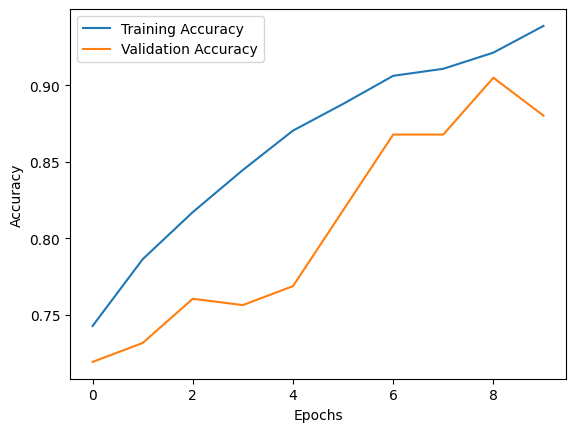

In [20]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

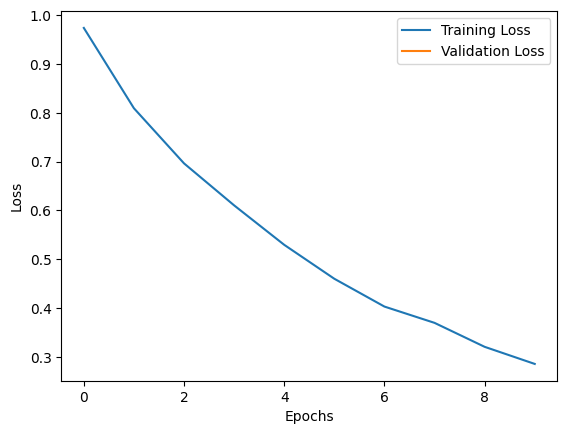

In [21]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()